# 03 — Retention Targeting and Campaign Economics
## Who Deserves the Next Retention Dollar?

This notebook combines customer value and predicted nonrepeat risk to identify retention candidates at September 10, 2011. The targeting policy is exploratory because it was refined after examining historical test outcomes. Financial results are hypothetical scenarios, not measured campaign ROI.

## 1. Load and validate customer data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT = Path('outputs')
SCORES_PATH = OUTPUT / '02_historical_test_customer_scores.csv'
RFM_PATH = OUTPUT / '01_customer_rfm_snapshot.csv'
for path in [SCORES_PATH, RFM_PATH]:
    if not path.exists():
        raise FileNotFoundError(f'Missing {path}. Run Notebooks 01 and 02 first.')

scores = pd.read_csv(SCORES_PATH)
segments = pd.read_csv(RFM_PATH)
required = {'Customer ID', 'RecencyDays', 'Frequency', 'MonetaryGBP',
            'HistoricalSpendGBP', 'PredictedRepeat90d', 'PredictedNoRepeat90d', 'Repeat90d'}
assert required.issubset(scores.columns), f'Missing score columns: {required - set(scores.columns)}'
assert {'Customer ID', 'Segment'}.issubset(segments.columns)
assert scores['Customer ID'].is_unique and segments['Customer ID'].is_unique
assert np.allclose(scores['PredictedRepeat90d'] + scores['PredictedNoRepeat90d'], 1, atol=1e-8)
assert scores['PredictedRepeat90d'].between(0, 1).all()
assert scores['Repeat90d'].isin([0, 1]).all()

customers = scores.merge(segments[['Customer ID', 'Segment']], on='Customer ID', how='left', validate='one_to_one')
assert customers['Segment'].notna().all(), 'Some scored customers have no segment; verify the snapshot dates.'
print(f'Customers: {len(customers):,} | Segments: {customers.Segment.nunique()}')
print(f'Historical test repeat rate: {customers.Repeat90d.mean():.1%}')
display(customers[['Customer ID','Segment','RecencyDays','HistoricalSpendGBP',
                   'PredictedRepeat90d','PredictedNoRepeat90d']].head())
assert set(scores['Customer ID']) == set(segments['Customer ID'])
check = scores.merge(segments, on='Customer ID', suffixes=('_model','_rfm'), validate='one_to_one')
for col in ['RecencyDays','Frequency','MonetaryGBP','HistoricalSpendGBP']:
    assert np.allclose(check[col+'_model'], check[col+'_rfm']), f'Mismatch: {col}'
assert pd.to_datetime(scores['SnapshotDate']).eq(pd.Timestamp('2011-09-10')).all()
order_stats = pd.read_csv(OUTPUT/'01_order_value_summary.csv', index_col=0)['OrderValueGBP']
order_values = {'Conservative stress test':50.0, 'Historical Q1':float(order_stats.loc['25%']),
                'Historical median':float(order_stats.loc['50%']), 'Historical Q3':float(order_stats.loc['75%'])}
print(order_values)

Customers: 5,281 | Segments: 5
Historical test repeat rate: 43.4%


,Customer ID,Segment,RecencyDays,HistoricalSpendGBP,PredictedRepeat90d,PredictedNoRepeat90d
0,14911,Champions,2.407639,234125.25,0.995427,0.004573
1,17841,Champions,0.575000,53394.36,0.994866,0.005134
2,12748,Champions,0.444444,36987.41,0.994708,0.005292
3,14606,Champions,2.471528,28268.60,0.992070,0.007930
4,12971,Champions,1.415278,12948.20,0.989107,0.010893


{'Conservative stress test': 50.0, 'Historical Q1': 181.58, 'Historical median': 314.51, 'Historical Q3': 521.5550000000001}


## 2. Eligibility and customer ranking

Customers are eligible within 365 days of their last purchase. The maximum contact budget is 10% of the scored population, rounded up. The fixed-budget rule requires at least 50% predicted nonrepeat risk and ranks customers by historical spending capped at the 95th percentile, then by risk and customer ID. Unused slots remain unfilled. Historical spending is a value proxy, not future revenue.

In [2]:
MAX_RECENCY_DAYS = 365
RISK_FLOOR = .50
budget_n = int(np.ceil(.10 * len(customers)))
spend_cap = customers.HistoricalSpendGBP.quantile(.95)
customers['CappedHistoricalSpendGBP'] = customers.HistoricalSpendGBP.clip(upper=spend_cap)
customers['PriorityProxy'] = customers.PredictedNoRepeat90d * customers.CappedHistoricalSpendGBP
customers['RetentionEligible'] = customers.RecencyDays.le(MAX_RECENCY_DAYS)
customers['RiskQualified'] = customers.RetentionEligible & customers.PredictedNoRepeat90d.ge(RISK_FLOOR)
eligible = customers.loc[customers.RetentionEligible].copy()
def rank_value(pool, n):
    return pool.sort_values(['CappedHistoricalSpendGBP','PredictedNoRepeat90d','Customer ID'], ascending=[False,False,True]).head(n)
primary = rank_value(customers.loc[customers.RiskQualified], budget_n)
n_contacts = len(primary)
assert n_contacts > 0
customers['Selected'] = customers['Customer ID'].isin(primary['Customer ID'])
print(f'Eligible: {len(eligible):,}; dormant: {len(customers)-len(eligible):,}; risk qualified: {customers.RiskQualified.sum():,}')
print(f'Budget: {budget_n}; selected: {n_contacts}; unused slots: {budget_n-n_contacts}; cap: £{spend_cap:,.2f}')

Eligible: 4,317; dormant: 964; risk qualified: 3,022
Budget: 529; selected: 529; unused slots: 0; cap: £8,729.38


## 3. Targeting strategy comparison

The risk-floor strategy is compared with the risk-times-value proxy, spending-only, risk-only and random eligible benchmarks at the same contact count. Random averages are population expectations; its median is the eligible population median. Observed outcomes are used for retrospective assessment, not individual ranking.

,Strategy,Customers,MedianHistoricalSpendGBP,MeanHistoricalSpendGBP,HistoricalGrossSpendGBP,MeanPredictedNoRepeat,ObservedNoRepeatRate,ObservedRepeatRate
0,Risk floor then value,529,3365.12,5093.775,2694606.716,0.707,0.388,0.612
1,Original value-at-risk proxy,529,5210.42,7448.930,3940483.957,0.619,0.323,0.677
2,Historical spend only,529,8377.32,16857.201,8917459.518,0.341,0.144,0.856
3,Nonrepeat risk only,529,501.21,878.697,464830.661,0.867,0.732,0.268
4,Random eligible benchmark,529,1017.03,3163.919,1673712.950,0.626,0.494,0.506


,Risk floor then value,Original value-at-risk proxy,Historical spend only,Nonrepeat risk only
Segment,,,,
At Risk / High Value,327,265,92,39
Champions,0,107,358,0
Inactive / Low Frequency,18,0,0,490
Loyal,65,84,48,0
Recent / Occasional,119,73,31,0


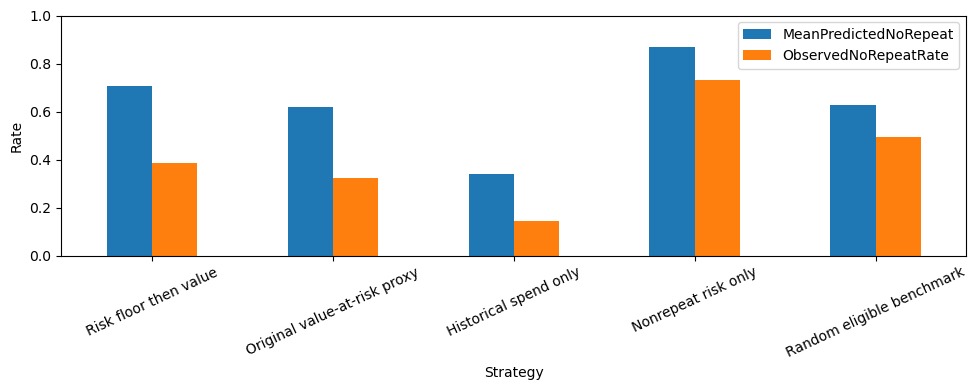

In [3]:
def top(pool, col, n):
    return pool.sort_values([col,'Customer ID'], ascending=[False,True]).head(n)
strategies = {'Risk floor then value':primary,
              'Original value-at-risk proxy':top(eligible,'PriorityProxy',n_contacts),
              'Historical spend only':top(eligible,'HistoricalSpendGBP',n_contacts),
              'Nonrepeat risk only':top(eligible,'PredictedNoRepeat90d',n_contacts)}
def summarize(name, pool, n):
    return {'Strategy':name,'Customers':n,'MedianHistoricalSpendGBP':pool.HistoricalSpendGBP.median(),
            'MeanHistoricalSpendGBP':pool.HistoricalSpendGBP.mean(),
            'HistoricalGrossSpendGBP':pool.HistoricalSpendGBP.mean()*n,
            'MeanPredictedNoRepeat':pool.PredictedNoRepeat90d.mean(),
            'ObservedNoRepeatRate':1-pool.Repeat90d.mean(),
            'ObservedRepeatRate':pool.Repeat90d.mean()}
comparison = pd.DataFrame([summarize(k,v,n_contacts) for k,v in strategies.items()] +
                          [summarize('Random eligible benchmark',eligible,n_contacts)])
display(comparison.round(3))
segment_mix = pd.DataFrame({k:v.Segment.value_counts() for k,v in strategies.items()}).fillna(0).astype(int)
display(segment_mix)
comparison.set_index('Strategy')[['MeanPredictedNoRepeat','ObservedNoRepeatRate']].plot.bar(figsize=(10,4),ylim=(0,1),rot=25)
plt.ylabel('Rate'); plt.tight_layout(); plt.show()

## 4. Eligibility and risk sensitivity

Alternative recency limits and risk floors illustrate the trade-off between customer value, risk and contact capacity. The comparisons are exploratory rather than an independent threshold optimization.

In [4]:
rows = []
primary_ids = set(primary['Customer ID'])
for days in [180,365,None]:
    pool = customers if days is None else customers.loc[customers.RecencyDays.le(days)]
    for floor in [.40,.50,.60]:
        qualified = pool.loc[pool.PredictedNoRepeat90d.ge(floor)]
        selected = rank_value(qualified,budget_n)
        row = summarize('Risk floor then value',selected,len(selected))
        row.update({'MaxRecencyDays':str(days) if days is not None else 'Unrestricted', 'RiskFloor':floor,
                    'EligibleCustomers':len(pool),'QualifiedCustomers':len(qualified),
                    'UnusedSlots':budget_n-len(selected),
                    'OverlapWithPrimaryPct':100*len(set(selected['Customer ID']) & primary_ids)/n_contacts})
        rows.append(row)
sensitivity = pd.DataFrame(rows)
display(sensitivity.round(3))

,Strategy,Customers,MedianHistoricalSpendGBP,MeanHistoricalSpendGBP,HistoricalGrossSpendGBP,MeanPredictedNoRepeat,ObservedNoRepeatRate,ObservedRepeatRate,MaxRecencyDays,RiskFloor,EligibleCustomers,QualifiedCustomers,UnusedSlots,OverlapWithPrimaryPct
0,Risk floor then value,529,3371.45,4657.641,2463891.927,0.587,0.299,0.701,180,0.4,2787,1941,0,67.297
1,Risk floor then value,529,2623.82,3861.853,2042920.105,0.642,0.363,0.637,180,0.5,2787,1492,0,67.297
2,Risk floor then value,529,1979.87,2962.420,1567120.384,0.681,0.450,0.550,180,0.6,2787,1290,0,47.259
3,Risk floor then value,529,3859.18,5712.805,3022073.798,0.647,0.336,0.664,365,0.4,4317,3471,0,75.803
4,Risk floor then value,529,3365.12,5093.775,2694606.716,0.707,0.388,0.612,365,0.5,4317,3022,0,100.000
5,Risk floor then value,529,2836.31,4359.259,2306048.034,0.755,0.454,0.546,365,0.6,4317,2820,0,79.962
6,Risk floor then value,529,4016.66,5983.495,3165268.859,0.660,0.365,0.635,Unrestricted,0.4,5281,4435,0,71.456
7,Risk floor then value,529,3505.88,5395.384,2854158.187,0.721,0.416,0.584,Unrestricted,0.5,5281,3986,0,92.060
8,Risk floor then value,529,3006.62,4688.649,2480295.465,0.768,0.491,0.509,Unrestricted,0.6,5281,3784,0,79.962


## 5. Fixed-budget campaign economics

Both strategies assume the same incremental purchase probability u, one order per incremental buyer, order value V, gross margin g = 35%, discount d = 10% and contact cost c = £0.50. The assumed fraction q of otherwise-repeat buyers redeeming a discount is 0%, 10% or 20%. The unconditional nonincremental redemption probability r equals q times mean predicted repeat propensity. Incremental and otherwise-repeat buyers are assumed disjoint, and all incremental orders redeem.

Expected margin per contact = u × V × (g − d) − r × V × d − c. Break-even u = (r × V × d + c) / (V × (g − d)). Historical order values are scenario references. Equal incremental response isolates assumed discount leakage differences rather than measuring actual targeting effectiveness.

,Campaign,OrderValueScenario,OrderValueGBP,AssumedNaturalBuyerRedemption,AssumedNonincrementalRedemption,AssumedIncrementalPurchaseProbability,CustomersContacted,MeanPredictedRepeat,GrossMarginRate,DiscountRate,ContactCostGBP,ExpectedIncrementalOrders,ExpectedIncrementalRevenueGBP,ProjectedNetMarginPerContactGBP,ProjectedNetMarginGBP,BreakEvenIncrementalProbability
56,Targeted,Historical median,314.51,0.1,0.029,0.01,529,0.293,0.35,0.1,0.5,5.29,1663.758,-0.634,-335.225,0.018
57,Random eligible,Historical median,314.51,0.1,0.037,0.01,529,0.374,0.35,0.1,0.5,5.29,1663.758,-0.890,-470.771,0.021
58,Targeted,Historical median,314.51,0.1,0.029,0.03,529,0.293,0.35,0.1,0.5,15.87,4991.274,0.939,496.654,0.018
59,Random eligible,Historical median,314.51,0.1,0.037,0.03,529,0.374,0.35,0.1,0.5,15.87,4991.274,0.683,361.108,0.021
60,Targeted,Historical median,314.51,0.1,0.029,0.05,529,0.293,0.35,0.1,0.5,26.45,8318.790,2.511,1328.533,0.018
61,Random eligible,Historical median,314.51,0.1,0.037,0.05,529,0.374,0.35,0.1,0.5,26.45,8318.790,2.255,1192.987,0.021
62,Targeted,Historical median,314.51,0.1,0.029,0.08,529,0.293,0.35,0.1,0.5,42.32,13310.063,4.870,2576.352,0.018
63,Random eligible,Historical median,314.51,0.1,0.037,0.08,529,0.374,0.35,0.1,0.5,42.32,13310.063,4.614,2440.805,0.021


Campaign,OrderValueScenario,AssumedNaturalBuyerRedemption,AssumedIncrementalPurchaseProbability,Random eligible,Targeted,TargetedMinusRandomGBP
36,Historical median,0.0,0.01,151.44,151.44,0.00
37,Historical median,0.0,0.03,983.32,983.32,0.00
38,Historical median,0.0,0.05,1815.20,1815.20,0.00
39,Historical median,0.0,0.08,3063.02,3063.02,0.00
40,Historical median,0.1,0.01,-470.77,-335.22,135.55
41,Historical median,0.1,0.03,361.11,496.65,135.55
42,Historical median,0.1,0.05,1192.99,1328.53,135.55
43,Historical median,0.1,0.08,2440.81,2576.35,135.55
44,Historical median,0.2,0.01,-1092.98,-821.89,271.09
45,Historical median,0.2,0.03,-261.10,9.99,271.09


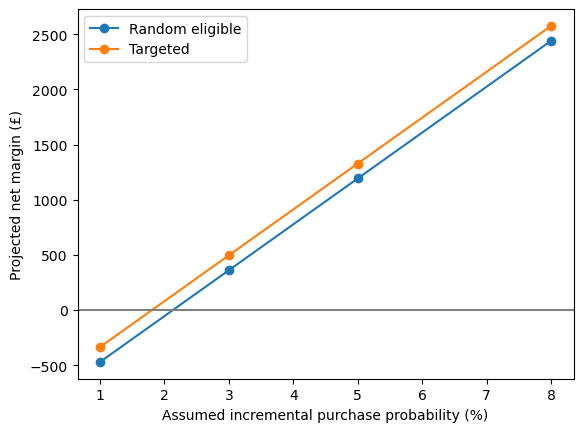

In [5]:
GROSS_MARGIN_RATE = .35
DISCOUNT_RATE = .10
CONTACT_COST_GBP = .50
rows = []
for label, value in order_values.items():
    for q in [0,.10,.20]:
        for uplift in [.01,.03,.05,.08]:
            for campaign,pool in [('Targeted',primary),('Random eligible',eligible)]:
                p_repeat = pool.PredictedRepeat90d.mean()
                r = q*p_repeat
                assert uplift <= 1-p_repeat  # group-level feasibility under assumed natural repeat rate
                margin = uplift*value*(GROSS_MARGIN_RATE-DISCOUNT_RATE)-r*value*DISCOUNT_RATE-CONTACT_COST_GBP
                rows.append({'Campaign':campaign,'OrderValueScenario':label,'OrderValueGBP':value,
                             'AssumedNaturalBuyerRedemption':q,'AssumedNonincrementalRedemption':r,
                             'AssumedIncrementalPurchaseProbability':uplift,'CustomersContacted':n_contacts,
                             'MeanPredictedRepeat':p_repeat,'GrossMarginRate':GROSS_MARGIN_RATE,'DiscountRate':DISCOUNT_RATE,
                             'ContactCostGBP':CONTACT_COST_GBP,'ExpectedIncrementalOrders':n_contacts*uplift,
                             'ExpectedIncrementalRevenueGBP':n_contacts*uplift*value,
                             'ProjectedNetMarginPerContactGBP':margin,'ProjectedNetMarginGBP':n_contacts*margin,
                             'BreakEvenIncrementalProbability':(r*value*DISCOUNT_RATE+CONTACT_COST_GBP)/(value*(GROSS_MARGIN_RATE-DISCOUNT_RATE))})
scenarios = pd.DataFrame(rows)
keys = ['OrderValueScenario','AssumedNaturalBuyerRedemption','AssumedIncrementalPurchaseProbability']
difference = scenarios.pivot(index=keys,columns='Campaign',values='ProjectedNetMarginGBP').reset_index()
difference['TargetedMinusRandomGBP'] = difference['Targeted']-difference['Random eligible']
display(scenarios.query("OrderValueScenario == 'Historical median' and AssumedNaturalBuyerRedemption == .10").round(3))
display(difference.query("OrderValueScenario == 'Historical median'").round(2))
plot_data = scenarios.query("OrderValueScenario == 'Historical median' and AssumedNaturalBuyerRedemption == .10")
for name, group in plot_data.groupby('Campaign'):
    plt.plot(group.AssumedIncrementalPurchaseProbability*100,group.ProjectedNetMarginGBP,marker='o',label=name)
plt.axhline(0,color='gray'); plt.xlabel('Assumed incremental purchase probability (%)'); plt.ylabel('Projected net margin (£)'); plt.legend(); plt.show()

## 6. Export targeting and financial summaries

Aggregate tables support public Tableau visualizations. Private customer-level exports exclude future outcomes and are separate from scenario-level tables.

In [6]:
crm_columns = ['Customer ID','SnapshotDate','Segment','RecencyDays','Frequency','MonetaryGBP','HistoricalSpendGBP','CappedHistoricalSpendGBP','PredictedRepeat90d','PredictedNoRepeat90d']
shortlist = primary[crm_columns].reset_index(drop=True).copy()
shortlist.insert(0,'PriorityRank',np.arange(1,len(shortlist)+1))
assert shortlist['Customer ID'].is_unique and shortlist.PredictedNoRepeat90d.ge(RISK_FLOOR).all()
assert shortlist.RecencyDays.le(MAX_RECENCY_DAYS).all()
shortlist.to_csv(OUTPUT/'03_historical_retention_shortlist_PRIVATE.csv',index=False)
customers[crm_columns+['RetentionEligible','RiskQualified','Selected']].to_csv(OUTPUT/'03_tableau_customers_PRIVATE.csv',index=False)
comparison.to_csv(OUTPUT/'03_targeting_strategy_comparison.csv',index=False)
segment_mix.to_csv(OUTPUT/'03_targeting_segment_mix.csv')
sensitivity.to_csv(OUTPUT/'03_eligibility_sensitivity.csv',index=False)
scenarios.to_csv(OUTPUT/'03_margin_scenarios.csv',index=False)
difference.to_csv(OUTPUT/'03_margin_comparison.csv',index=False)
customers.groupby('Segment').agg(Customers=('Customer ID','size'),Eligible=('RetentionEligible','sum'),RiskQualified=('RiskQualified','sum'),Selected=('Selected','sum')).reset_index().to_csv(OUTPUT/'03_tableau_segment_overview.csv',index=False)
print('Exports saved:', OUTPUT.resolve())
display(shortlist.head(10))

Exports saved: C:\Users\user\Documents\Wright\Capstone\Capstone Project\retention-scoring-capstone\outputs


,PriorityRank,Customer ID,SnapshotDate,Segment,RecencyDays,Frequency,MonetaryGBP,HistoricalSpendGBP,CappedHistoricalSpendGBP,PredictedRepeat90d,PredictedNoRepeat90d
0,1,18251,2011-09-10,At Risk / High Value,354.440278,0,0.0,21964.14,8729.38,0.128254,0.871746
1,2,14063,2011-09-10,At Risk / High Value,347.320833,0,0.0,22710.20,8729.38,0.129845,0.870155
2,3,13687,2011-09-10,At Risk / High Value,347.312500,0,0.0,11880.84,8729.38,0.129847,0.870153
3,4,12454,2011-09-10,At Risk / High Value,304.577083,0,0.0,13151.44,8729.38,0.139748,0.860252
4,5,12357,2011-09-10,At Risk / High Value,297.396528,0,0.0,12079.99,8729.38,0.141472,0.858528
5,6,15523,2011-09-10,At Risk / High Value,297.356250,0,0.0,16947.98,8729.38,0.141482,0.858518
6,7,14134,2011-09-10,At Risk / High Value,291.481944,0,0.0,11123.35,8729.38,0.142906,0.857094
7,8,17044,2011-09-10,At Risk / High Value,283.550000,0,0.0,11013.82,8729.38,0.144848,0.855152
8,9,17850,2011-09-10,At Risk / High Value,281.356250,0,0.0,56600.08,8729.38,0.145388,0.854612
9,10,16754,2011-09-10,At Risk / High Value,281.265278,0,0.0,67502.47,8729.38,0.145411,0.854589


## 7. Fixed-budget targeting findings

The 529-customer risk-floor strategy has a higher observed nonrepeat rate than the risk-times-value proxy (38.8% versus 32.3%), but a lower rate than the random eligible benchmark (49.4%). Its median historical spending is higher than the random benchmark. This reflects a trade-off between historical value and nonrepeat risk, not evidence of incremental offer response.

## 8. Customer treatment matrix

The matrix combines the 50% predicted nonrepeat threshold with the historical spending 75th percentile. Customers dormant for more than 365 days form a separate group. The groups represent proposed marketing treatments, not automatic discount eligibility.

In [7]:
value_floor = customers.HistoricalSpendGBP.quantile(.75)
high_value = customers.HistoricalSpendGBP.ge(value_floor)
high_risk = customers.PredictedNoRepeat90d.ge(RISK_FLOOR)
customers['TreatmentGroup'] = np.select(
    [~customers.RetentionEligible, high_value & high_risk, high_value & ~high_risk,
     ~high_value & high_risk],
    ['Separate reactivation', 'Retention pilot candidates', 'Protect loyalty',
     'Low-cost outreach'], default='Nurture')
actions = {'Separate reactivation':'Separate reactivation test',
           'Retention pilot candidates':'Randomized offer versus no-offer pilot',
           'Protect loyalty':'Recognition and service; avoid routine discounts',
           'Low-cost outreach':'Automated low-cost engagement',
           'Nurture':'Regular marketing communication'}
customers['ProposedAction'] = customers.TreatmentGroup.map(actions)
matrix = customers.groupby('TreatmentGroup').agg(
    Customers=('Customer ID','size'), Selected=('Selected','sum'),
    MedianHistoricalSpendGBP=('HistoricalSpendGBP','median'),
    HistoricalGrossSpendGBP=('HistoricalSpendGBP','sum'),
    MeanPredictedRepeat=('PredictedRepeat90d','mean'),
    ObservedRepeatRate=('Repeat90d','mean')).reset_index()
matrix['ObservedNoRepeatRate'] = 1-matrix.ObservedRepeatRate
matrix['ProposedAction'] = matrix.TreatmentGroup.map(actions)
assert matrix.Customers.sum() == len(customers)
assert matrix.Selected.sum() == n_contacts
print(f'High-value threshold: £{value_floor:,.2f}')
display(matrix.round(3))
matrix.to_csv(OUTPUT/'03_treatment_matrix.csv',index=False)
customers[crm_columns+['RetentionEligible','RiskQualified','Selected','TreatmentGroup','ProposedAction']].to_csv(OUTPUT/'03_tableau_customers_PRIVATE.csv',index=False)
shortlist.merge(customers[['Customer ID','TreatmentGroup','ProposedAction']],on='Customer ID',validate='one_to_one').to_csv(OUTPUT/'03_historical_retention_shortlist_PRIVATE.csv',index=False)

High-value threshold: £2,118.75


,TreatmentGroup,Customers,Selected,MedianHistoricalSpendGBP,HistoricalGrossSpendGBP,MeanPredictedRepeat,ObservedRepeatRate,ObservedNoRepeatRate,ProposedAction
0,Low-cost outreach,2521,28,548.49,1772973.582,0.236,0.347,0.653,Automated low-cost engagement
1,Nurture,520,0,980.20,549222.681,0.602,0.633,0.367,Regular marketing communication
2,Protect loyalty,775,0,5036.53,8700271.475,0.721,0.866,0.134,Recognition and service; avoid routine discounts
3,Retention pilot candidates,501,501,3490.24,2636168.946,0.294,0.621,0.379,Randomized offer versus no-offer pilot
4,Separate reactivation,964,0,305.71,628771.772,0.101,0.108,0.892,Separate reactivation test


## 9. Financial robustness analysis

Observed repeat rates provide a retrospective stress test of the predicted-rate scenarios, with all other assumptions held constant. Historical outcomes were unavailable at selection time and are not verified untreated counterfactuals.

Campaign,OrderValueScenario,AssumedNaturalBuyerRedemption,AssumedIncrementalPurchaseProbability,RepeatRateBasis,Random eligible,Targeted,TargetedMinusRandomGBP
80,Historical median,0.1,0.01,Observed retrospective,-691.04,-867.57,-176.54
81,Historical median,0.1,0.01,Predicted,-470.77,-335.22,135.55
82,Historical median,0.1,0.03,Observed retrospective,140.84,-35.69,-176.54
83,Historical median,0.1,0.03,Predicted,361.11,496.65,135.55
84,Historical median,0.1,0.05,Observed retrospective,972.72,796.18,-176.54
85,Historical median,0.1,0.05,Predicted,1192.99,1328.53,135.55
86,Historical median,0.1,0.08,Observed retrospective,2220.54,2044.00,-176.54
87,Historical median,0.1,0.08,Predicted,2440.81,2576.35,135.55


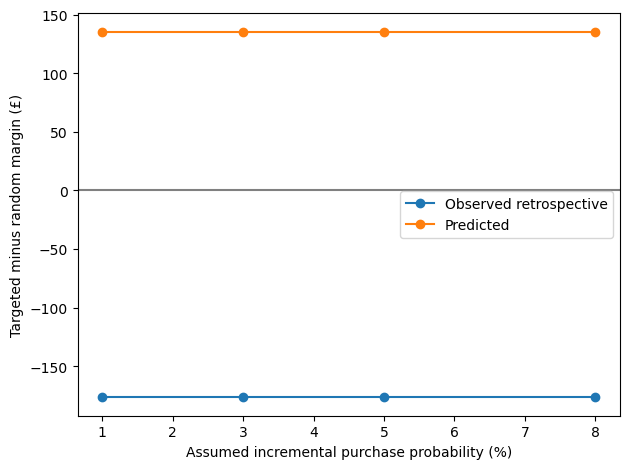

In [8]:
robust_rows = []
for row in scenarios.to_dict('records'):
    pool = primary if row['Campaign']=='Targeted' else eligible
    for basis, p in [('Predicted',pool.PredictedRepeat90d.mean()),
                     ('Observed retrospective',pool.Repeat90d.mean())]:
        V = row['OrderValueGBP']
        q = row['AssumedNaturalBuyerRedemption']
        u = row['AssumedIncrementalPurchaseProbability']
        assert u <= 1-p
        leakage = q*p
        margin = u*V*(GROSS_MARGIN_RATE-DISCOUNT_RATE)-leakage*V*DISCOUNT_RATE-CONTACT_COST_GBP
        robust_rows.append({**row,'RepeatRateBasis':basis,'RepeatRateUsed':p,
            'AssumedNonincrementalRedemption':leakage,
            'ProjectedNetMarginPerContactGBP':margin,'ProjectedNetMarginGBP':n_contacts*margin,
            'BreakEvenIncrementalProbability':(leakage*V*DISCOUNT_RATE+CONTACT_COST_GBP)/(V*(GROSS_MARGIN_RATE-DISCOUNT_RATE))})
robustness = pd.DataFrame(robust_rows)
robust_difference = robustness.pivot(index=keys+['RepeatRateBasis'],columns='Campaign',values='ProjectedNetMarginGBP').reset_index()
robust_difference['TargetedMinusRandomGBP'] = robust_difference['Targeted']-robust_difference['Random eligible']
assert np.allclose(robust_difference.loc[robust_difference.AssumedNaturalBuyerRedemption.eq(0),'TargetedMinusRandomGBP'],0)
example = robust_difference.query("OrderValueScenario == 'Historical median' and AssumedNaturalBuyerRedemption == .10")
display(example.round(2))
for basis, group in example.groupby('RepeatRateBasis'):
    plt.plot(group.AssumedIncrementalPurchaseProbability*100,group.TargetedMinusRandomGBP,marker='o',label=basis)
plt.axhline(0,color='gray'); plt.xlabel('Assumed incremental purchase probability (%)'); plt.ylabel('Targeted minus random margin (£)'); plt.legend(); plt.tight_layout(); plt.show()
robustness.to_csv(OUTPUT/'03_margin_robustness.csv',index=False)
robust_difference.to_csv(OUTPUT/'03_margin_robustness_comparison.csv',index=False)

## 10. Financial analysis of the 501-customer pilot audience

The primary candidate audience is compared with an equally sized random eligible benchmark using population expectations. Both predicted and observed repeat-rate assumptions are evaluated. The 529-contact strategy remains a separate comparison. Full-audience scenarios illustrate potential rollout economics, not the size of a randomized treatment arm.

Pilot candidates: 501; unused contact slots: 28


,Campaign,RepeatRateBasis,RepeatRateUsed,AssumedIncrementalPurchaseProbability,ProjectedNetMarginGBP,BreakEvenIncrementalProbability
112,Pilot candidates,Predicted,0.2940,0.01,-319.7961,0.0181
113,Pilot candidates,Observed retrospective,0.6208,0.01,-834.7023,0.0312
114,Random eligible,Predicted,0.3740,0.01,-445.8534,0.0213
115,Random eligible,Observed retrospective,0.5064,0.01,-654.4612,0.0266
116,Pilot candidates,Predicted,0.2940,0.03,468.0514,0.0181
117,Pilot candidates,Observed retrospective,0.6208,0.03,-46.8548,0.0312
118,Random eligible,Predicted,0.3740,0.03,341.9942,0.0213
119,Random eligible,Observed retrospective,0.5064,0.03,133.3863,0.0266
120,Pilot candidates,Predicted,0.2940,0.05,1255.8990,0.0181
121,Pilot candidates,Observed retrospective,0.6208,0.05,740.9928,0.0312


Campaign,OrderValueScenario,AssumedNaturalBuyerRedemption,AssumedIncrementalPurchaseProbability,RepeatRateBasis,CustomersContacted,Pilot candidates,Random eligible,PilotMinusRandomGBP
80,Historical median,0.1,0.01,Observed retrospective,501,-834.70,-654.46,-180.24
81,Historical median,0.1,0.01,Predicted,501,-319.80,-445.85,126.06
82,Historical median,0.1,0.03,Observed retrospective,501,-46.85,133.39,-180.24
83,Historical median,0.1,0.03,Predicted,501,468.05,341.99,126.06
84,Historical median,0.1,0.05,Observed retrospective,501,740.99,921.23,-180.24
85,Historical median,0.1,0.05,Predicted,501,1255.90,1129.84,126.06
86,Historical median,0.1,0.08,Observed retrospective,501,1922.76,2103.01,-180.24
87,Historical median,0.1,0.08,Predicted,501,2437.67,2311.61,126.06


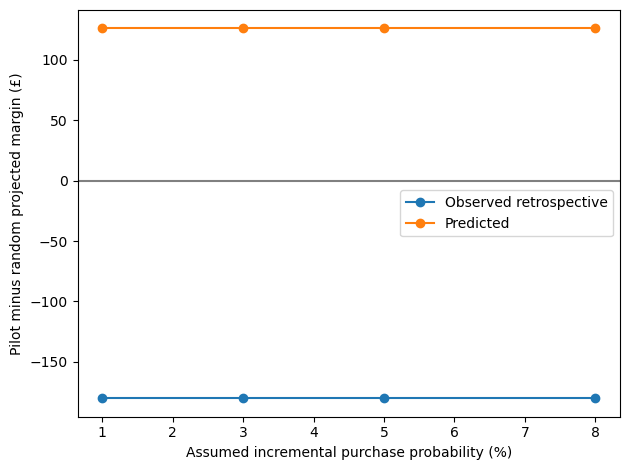

In [9]:
pilot = customers.loc[customers.TreatmentGroup.eq('Retention pilot candidates')].copy()
pilot_n = len(pilot)
assert 0 < pilot_n <= budget_n
assert pilot.RetentionEligible.all() and pilot.RiskQualified.all()
assert pilot.HistoricalSpendGBP.ge(value_floor).all()
print(f'Pilot candidates: {pilot_n:,}; unused contact slots: {budget_n-pilot_n:,}')

pilot_rows = []
for label, V in order_values.items():
    for q in [0, .10, .20]:
        for u in [.01, .03, .05, .08]:
            for campaign, pool in [('Pilot candidates', pilot), ('Random eligible', eligible)]:
                for basis, p in [('Predicted', pool.PredictedRepeat90d.mean()),
                                 ('Observed retrospective', pool.Repeat90d.mean())]:
                    assert u <= 1-p
                    leakage = q*p
                    margin = u*V*(GROSS_MARGIN_RATE-DISCOUNT_RATE)-leakage*V*DISCOUNT_RATE-CONTACT_COST_GBP
                    break_even = (leakage*V*DISCOUNT_RATE+CONTACT_COST_GBP)/(V*(GROSS_MARGIN_RATE-DISCOUNT_RATE))
                    pilot_rows.append({'Campaign': campaign, 'RepeatRateBasis': basis,
                        'RepeatRateUsed': p, 'OrderValueScenario': label, 'OrderValueGBP': V,
                        'AssumedNaturalBuyerRedemption': q, 'AssumedNonincrementalRedemption': leakage,
                        'AssumedIncrementalPurchaseProbability': u, 'CustomersContacted': pilot_n,
                        'GrossMarginRate': GROSS_MARGIN_RATE, 'DiscountRate': DISCOUNT_RATE,
                        'ContactCostGBP': CONTACT_COST_GBP, 'ExpectedIncrementalOrders': pilot_n*u,
                        'ExpectedIncrementalRevenueGBP': pilot_n*u*V,
                        'ProjectedNetMarginPerContactGBP': margin, 'ProjectedNetMarginGBP': pilot_n*margin,
                        'BreakEvenIncrementalProbability': break_even})
pilot_scenarios = pd.DataFrame(pilot_rows)
pilot_comparison = pilot_scenarios.pivot(index=keys+['RepeatRateBasis','CustomersContacted'],
    columns='Campaign', values='ProjectedNetMarginGBP').reset_index()
pilot_comparison['PilotMinusRandomGBP'] = pilot_comparison['Pilot candidates']-pilot_comparison['Random eligible']
assert len(pilot_scenarios) == len(order_values)*3*4*2*2
assert np.allclose(pilot_comparison.loc[pilot_comparison.AssumedNaturalBuyerRedemption.eq(0),'PilotMinusRandomGBP'],0)
example_pilot = pilot_scenarios.query("OrderValueScenario == 'Historical median' and AssumedNaturalBuyerRedemption == .10")
display(example_pilot[['Campaign','RepeatRateBasis','RepeatRateUsed','AssumedIncrementalPurchaseProbability',
    'ProjectedNetMarginGBP','BreakEvenIncrementalProbability']].round(4))
example_comparison = pilot_comparison.query("OrderValueScenario == 'Historical median' and AssumedNaturalBuyerRedemption == .10")
display(example_comparison.round(2))
for basis, group in example_comparison.groupby('RepeatRateBasis'):
    plt.plot(group.AssumedIncrementalPurchaseProbability*100, group.PilotMinusRandomGBP, marker='o', label=basis)
plt.axhline(0,color='gray'); plt.xlabel('Assumed incremental purchase probability (%)')
plt.ylabel('Pilot minus random projected margin (£)'); plt.legend(); plt.tight_layout(); plt.show()
pilot_scenarios.to_csv(OUTPUT/'03_pilot_margin_scenarios.csv',index=False)
pilot_comparison.to_csv(OUTPUT/'03_pilot_margin_comparison.csv',index=False)
pilot_list = rank_value(pilot,pilot_n)[crm_columns+['TreatmentGroup','ProposedAction']].reset_index(drop=True)
pilot_list.insert(0,'PriorityRank',np.arange(1,pilot_n+1))
assert pilot_list['Customer ID'].is_unique
pilot_list.to_csv(OUTPUT/'03_retention_pilot_candidates_PRIVATE.csv',index=False)


## 11. Business findings and recommendation

The treatment matrix identifies 501 high-value, high-predicted-risk candidates. Their observed nonrepeat rate is 37.9%, compared with 13.4% among high-value customers with lower predicted risk. The remaining groups support loyalty maintenance, regular engagement, low-cost outreach or separate reactivation.

At the reference order value and 10% assumed otherwise-repeat buyer redemption, the pilot audience’s projected advantage over random selection reverses when observed repeat rates replace predicted rates. The financial advantage is therefore not robust.

A randomized offer versus no-offer experiment within the candidate audience is recommended to measure incremental 90-day purchases and net contribution after discounts and contact costs. Expansion would depend on measured incremental profit. Historical spending is not recoverable future revenue, and the exploratory targeting policy has not been independently validated.